# TabPFN — Régression sur California Housing

In [1]:
import sys
sys.path.append("../backend")

from data import load_split

d = load_split()
X_train, X_test = d["X_train"], d["X_test"]
y_train, y_test = d["y_train"], d["y_test"]
X_shap, X_background = d["X_shap"], d["X_background"]

In [2]:
# Entraînement TabPFN (paramètres par défaut, GPU Apple via MPS)
import time
from tabpfn import TabPFNRegressor

model = TabPFNRegressor(device="mps", random_state=42)

t0 = time.perf_counter()
model.fit(X_train, y_train)
fit_time = time.perf_counter() - t0
print(f"Temps de fit : {fit_time:.3f} s")

Temps de fit : 3.958 s


In [3]:
# Métriques sur le jeu de test
import numpy as np
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

t0 = time.perf_counter()
y_pred = model.predict(X_test)
predict_time = time.perf_counter() - t0

metrics_tabpfn = {
    "rmse": float(np.sqrt(mean_squared_error(y_test, y_pred))),
    "mae": float(mean_absolute_error(y_test, y_pred)),
    "r2": float(r2_score(y_test, y_pred)),
    "fit_time": fit_time,
    "predict_time": predict_time,
}
metrics_tabpfn

{'rmse': 0.42754540027306037,
 'mae': 0.2655730131311867,
 'r2': 0.8678332581148003,
 'fit_time': 3.958095208003215,
 'predict_time': 10.54923829100153}

In [4]:
# SHAP : test sur 5 points pour estimer le temps de calcul
import shap

MAX_EVALS = 100  # 500 par défaut : réduit pour tenir en ~45 min sur 100 points

explainer = shap.PermutationExplainer(model.predict, X_background)

t0 = time.perf_counter()
shap_test = explainer(X_shap.iloc[:5], max_evals=MAX_EVALS)
t5 = time.perf_counter() - t0
print(f"Background : {len(X_background)} lignes, max_evals : {MAX_EVALS}")
print(f"5 points : {t5:.1f} s → estimation pour 100 points : {t5 * 20 / 60:.1f} min")

PermutationExplainer explainer: 6it [04:18, 51.72s/it]                       

Background : 20 lignes, max_evals : 100
5 points : 258.6 s → estimation pour 100 points : 86.2 min


In [5]:
# Vérification de l'additivité : base value + somme des SHAP = prédiction
recon = shap_test.base_values + shap_test.values.sum(axis=1)
print("Additivité OK :", np.allclose(recon, model.predict(X_shap.iloc[:5]), atol=1e-3))

Additivité OK : True


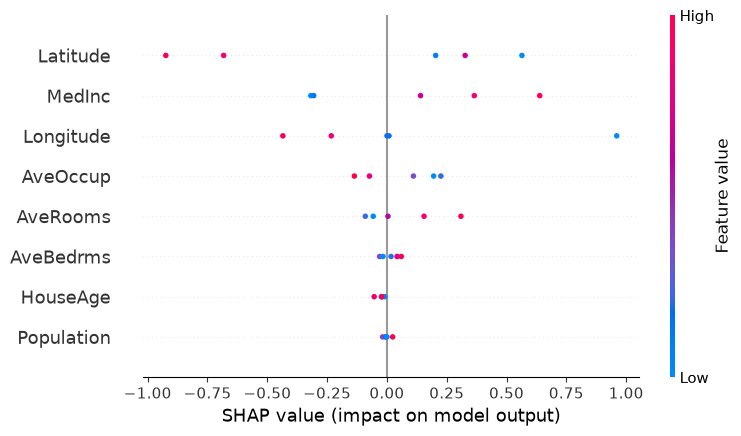

In [6]:
# Beeswarm de contrôle (5 points seulement : le vrai sera calculé dans le pipeline)
shap.plots.beeswarm(shap_test)

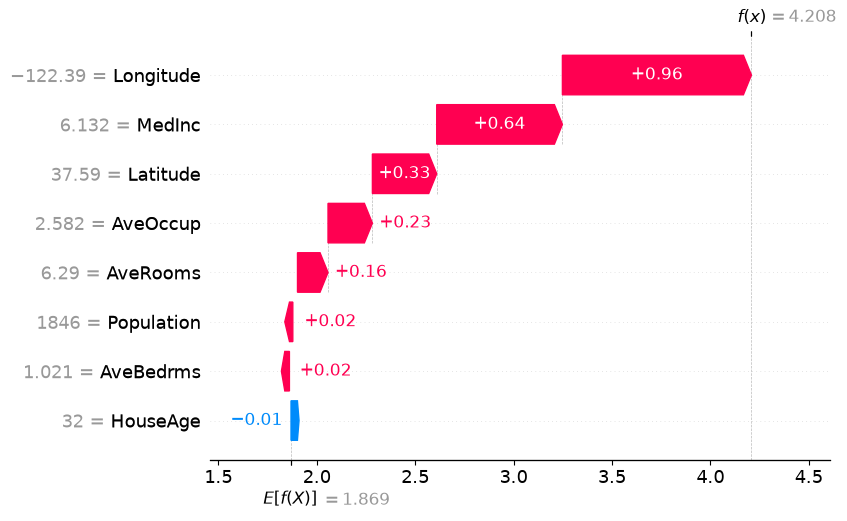

In [7]:
# Waterfall : détail d'une prédiction (point 0)
shap.plots.waterfall(shap_test[0])